# Lab: Relationships Between Quantitative Features

Use a historical mammal sleep dataset to compare dreaming, non-dreaming, and total sleep. Use non-dreaming versus total sleep as the main model, then examine whether danger and predation ratings add information. Finally, investigate the nonlinear pattern between gestation time and total sleep.

Support conclusions with the plots and calculations. Explain how well a straight line follows the points and how much variation remains.

## Learning goals

- Describe whether points trend upward or downward, follow a straight or curved pattern, cluster closely around that pattern, or include unusual observations.
- Calculate correlation and interpret R-squared on the correct response scale.
- Recognize nonlinear patterns and compare original gestation with log-transformed gestation.
- Examine additional categorical features visually and compare model R-squared on the same observations.
- Check missing codes, units, category counts, and transformations.
- Distinguish improved fit to observed records from causation and performance on new data.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can answer it?
3. **Evidence:** What should we calculate and display?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete each investigation in order. Use separate cells for individual operations and add cells as needed. Give figures informative titles, named colors, and axis labels with units or transformations. Use the default point transparency and line widths. `ci=None` can omit confidence bands so the patterns and group lines are easier to compare.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code and checking every claim against the source and your output. Complete the AI-use reflection at the end.

## Dataset and context

Use the [StatLib mammal sleep data hosted by UC Berkeley](https://www.stat.berkeley.edu/~spector/s100/data/sleep.dat) and its [measurement dictionary](https://www.stat.berkeley.edu/~spector/s100/data/sleep.html). A local copy is supplied as `data/mammal_sleep.csv`.

The supplied `data/mammal_sleep.csv` contains all 62 records and 11 features, including species names and both sleep phases. One row describes a mammal species, not an individual animal or a night. The data trace to Allison and Cicchetti's 1976 study, [Sleep in mammals: ecological and constitutional correlates](https://pubmed.ncbi.nlm.nih.gov/982039/). This is a historical comparative dataset, not a random sample of all mammals; individual collection dates are not supplied.

Course preparation preserves all values and names, gives columns descriptive names, and converts the source's `-999` missing code into blank CSV fields. Use ordinary `pd.read_csv()`; blanks are recognized as missing. The terms dreaming and non-dreaming identify the study's sleep-phase measurements; they are not direct reports of an animal's subjective dream experiences.

### Data dictionary

| Feature | Meaning and units or codes |
| --- | --- |
| `species` | Species label as recorded in the historical source |
| `non_dreaming_sleep` | Non-dreaming sleep in hours per day |
| `dreaming_sleep` | Dreaming sleep in hours per day |
| `body_weight` | Body weight in kilograms |
| `brain_weight` | Brain weight in grams |
| `max_life_span` | Maximum lifespan in years |
| `gestation_time` | Gestation duration in days |
| `predation_index` | Ordered rating, 1–5: lower to higher likelihood of being preyed upon |
| `sleep_exposure_index` | Ordered rating, 1–5: more protected to more exposed sleeping conditions |
| `danger_index` | Ordered rating, 1–5: lower to higher overall danger from other animals |
| `total_sleep` | Total sleep in hours per day; sum of the two phases |

The indices are **ordinal categorical features**, even though stored as numbers. A one-point difference is not a documented equal increment of physical risk. Overall danger incorporates predation, sleep exposure, and other information, so these ratings are not independent measurements. In our models, represent rating levels as categories rather than assuming equal numerical spacing.

## Load and inspect the data

In [1]:
# Import NumPy, Pandas, Matplotlib pyplot, and Seaborn.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Read data/mammal_sleep.csv into mammals_df; blank fields are recognized as missing.
mammals_df = pd.read_csv("mammal_sleep.csv")
mammals_df.head()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
0,African elephant,6654.000,5712.0,NaN,NaN,3.3,38.6,645.0,3,5,3
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3
2,Arctic Fox,3.385,44.5,NaN,NaN,12.5,14.0,60.0,1,1,1
3,Arctic ground squirrel,0.920,5.7,NaN,NaN,16.5,NaN,25.0,5,2,3
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4


In [3]:
# Display the first five rows.
mammals_df.tail()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
57,Tree hyrax,2.000,12.3,4.9,0.5,5.4,7.5,200.0,3,1,3
58,Tree shrew,0.104,2.5,13.2,2.6,15.8,2.3,46.0,3,2,2
59,Vervet,4.190,58.0,9.7,0.6,10.3,24.0,210.0,4,3,4
60,Water opossum,3.500,3.9,12.8,6.6,19.4,3.0,14.0,2,1,1
61,Yellow-bellied marmot,4.050,17.0,NaN,NaN,NaN,13.0,38.0,3,1,1


In [4]:
# Display the last five rows.
mammals_df.shape

(62, 11)

In [5]:
# Display the shape.
mammals_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   species               62 non-null     object 
 1   body_weight           62 non-null     float64
 2   brain_weight          62 non-null     float64
 3   non_dreaming_sleep    48 non-null     float64
 4   dreaming_sleep        50 non-null     float64
 5   total_sleep           58 non-null     float64
 6   max_life_span         58 non-null     float64
 7   gestation_time        58 non-null     float64
 8   predation_index       62 non-null     int64  
 9   sleep_exposure_index  62 non-null     int64  
 10  danger_index          62 non-null     int64  
dtypes: float64(7), int64(3), object(1)
memory usage: 5.5+ KB


In [6]:
# Use .info() to inspect the data storage types and non-missing values.
mammals_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   species               62 non-null     object 
 1   body_weight           62 non-null     float64
 2   brain_weight          62 non-null     float64
 3   non_dreaming_sleep    48 non-null     float64
 4   dreaming_sleep        50 non-null     float64
 5   total_sleep           58 non-null     float64
 6   max_life_span         58 non-null     float64
 7   gestation_time        58 non-null     float64
 8   predation_index       62 non-null     int64  
 9   sleep_exposure_index  62 non-null     int64  
 10  danger_index          62 non-null     int64  
dtypes: float64(7), int64(3), object(1)
memory usage: 5.5+ KB


In [7]:
# Count missing values in every feature.
mammals_df.isnull().sum()

species                  0
body_weight              0
brain_weight             0
non_dreaming_sleep      14
dreaming_sleep          12
total_sleep              4
max_life_span            4
gestation_time           4
predation_index          0
sleep_exposure_index     0
danger_index             0
dtype: int64

**What does one row represent?**

Your answer:  Each row represents one mammal species and its recorded sleep patterns, physical characteristics, and environmental risk ratings. It does not represent an individual animal.

**Complete the table using the data dictionary, `.info()`, and `.isnull().sum()`. For data type, use categorical or quantitative. For data storage type, report the Pandas dtype. For missing values, report the count, including 0 when none are missing.**

| Feature | Data type | Data storage type | Missing values |
|---|---|---|---:|
| species | Categorical | object | 0 |
| non_dreaming_sleep | Quantitative | float64 | 14 |
| dreaming_sleep | Quantitative | float64 | 12 |
| body_weight | Quantitative | float64 | 0 |
| brain_weight | Quantitative | float64 | 0 |
| max_life_span | Quantitative | float64 | 4 |
| gestation_time | Quantitative | float64 | 4 |
| predation_index | Categorical | int64 | 0 |
| sleep_exposure_index | Categorical | int64 | 0 |
| danger_index | Categorical | int64 | 0 |
| total_sleep | Quantitative | float64 | 4 |


# Investigation 1: Dreaming, non-dreaming, and total sleep

## Step 1: Question

**How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?**

Compare three relationships in hours per day: dreaming versus non-dreaming, dreaming versus total, and non-dreaming versus total. In the last comparison, use non-dreaming sleep on the horizontal axis and total sleep as the response. This is the main model for Investigation 2.

**Predict the direction and strength of each relationship. Which phase do you expect to be more strongly related to total sleep, and why?**

Your answer: I predict positive relationships between dreaming, non-dreaming, and total sleep. Mammals that spend more time sleeping overall will probably spend more time in both sleep phases. I expect non-dreaming sleep to have the strongest relationship with total sleep because it generally accounts for a larger portion of total sleep time.

## Step 2: Data

Create `sleep_df` from records complete for `dreaming_sleep`, `non_dreaming_sleep`, `total_sleep`, `danger_index`, and `predation_index`. Use `.copy()` and keep `mammals_df` unchanged. Use this same subset in all three comparisons and in Investigation 2. How many records were removed from the dataset?

Check that sleep measurements are between 0 and 24 hours per day.

In [8]:
# Prepare sleep_df and check sample size and sleep ranges.
sleep_columns = [
    "dreaming_sleep",
    "non_dreaming_sleep",
    "total_sleep",
    "danger_index",
    "predation_index"
]

sleep_df = mammals_df.dropna(subset=sleep_columns).copy()

print("Original records:", len(mammals_df))
print("Complete records:", len(sleep_df))
print("Records removed:", len(mammals_df) - len(sleep_df))

print("\nSleep measurement ranges:")
print(sleep_df[[
    "dreaming_sleep",
    "non_dreaming_sleep",
    "total_sleep"
]].agg(["min", "max"]))

print("\nAll sleep values between 0 and 24:")
print(sleep_df[[
    "dreaming_sleep",
    "non_dreaming_sleep",
    "total_sleep"
]].ge(0).all().all() and
      sleep_df[[
          "dreaming_sleep",
          "non_dreaming_sleep",
          "total_sleep"
      ]].le(24).all().all())

Original records: 62
Complete records: 48
Records removed: 14

Sleep measurement ranges:
     dreaming_sleep  non_dreaming_sleep  total_sleep
min             0.0                 2.1          2.9
max             6.6                17.9         19.9

All sleep values between 0 and 24:
True


## Step 3: Evidence

Create three labeled regression plots with `sns.regplot()`: non-dreaming sleep versus dreaming sleep, total sleep versus dreaming sleep, and total sleep versus non-dreaming sleep. In each description, the feature after “versus” goes on the horizontal axis. Calculate the correlation and simple-line R-squared for each pair. Describe the points before relying on the fitted line.

When describing a scatterplot:

- **Direction:** Do the points generally rise or fall from left to right?
- **Form:** Does the overall pattern look roughly straight, curved, or have no clear shape? This describes the arrangement of the points, not the line drawn by the plotting function.
- **Strength:** How closely do the points follow that pattern?
- **Unusual observations:** Which points are far from most of the others?

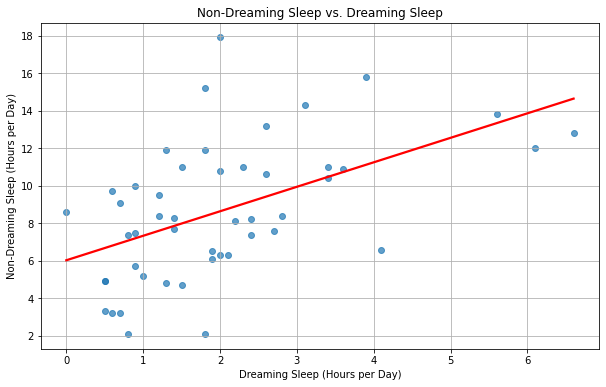

In [9]:
# Plot dreaming sleep and non-dreaming sleep.
plt.figure(figsize=(10, 6))

sns.regplot(
    data=sleep_df,
    x="dreaming_sleep",
    y="non_dreaming_sleep",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"},
    ci=None
)

plt.title("Non-Dreaming Sleep vs. Dreaming Sleep")
plt.xlabel("Dreaming Sleep (Hours per Day)")
plt.ylabel("Non-Dreaming Sleep (Hours per Day)")
plt.grid(True)
plt.show()

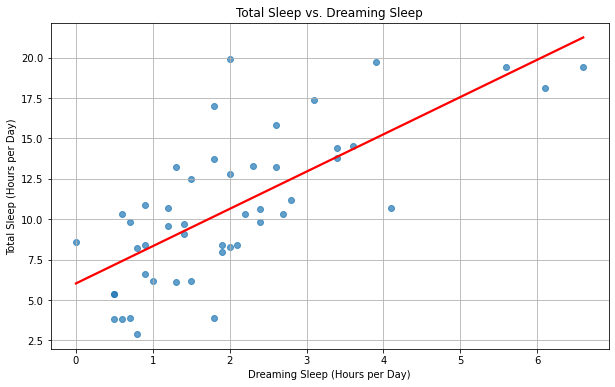

In [10]:
# Plot dreaming sleep and total sleep.
plt.figure(figsize=(10, 6))

sns.regplot(
    data=sleep_df,
    x="dreaming_sleep",
    y="total_sleep",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"},
    ci=None
)

plt.title("Total Sleep vs. Dreaming Sleep")
plt.xlabel("Dreaming Sleep (Hours per Day)")
plt.ylabel("Total Sleep (Hours per Day)")
plt.grid(True)
plt.show()

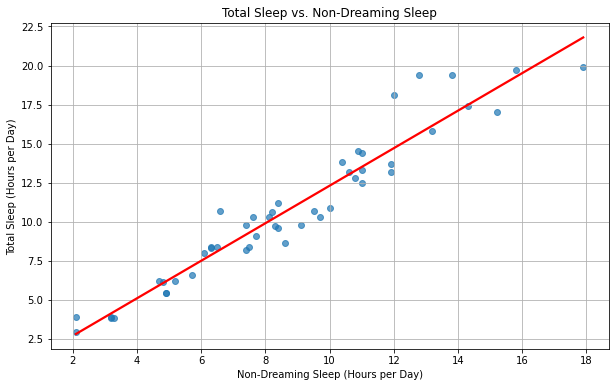

In [11]:
# Plot non-dreaming sleep and total sleep.
plt.figure(figsize=(10, 6))

sns.regplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"},
    ci=None
)

plt.title("Total Sleep vs. Non-Dreaming Sleep")
plt.xlabel("Non-Dreaming Sleep (Hours per Day)")
plt.ylabel("Total Sleep (Hours per Day)")
plt.grid(True)
plt.show()

In [12]:
# Calculate all three correlations and R-squared values.
pairs = [
    ("dreaming_sleep", "non_dreaming_sleep"),
    ("dreaming_sleep", "total_sleep"),
    ("non_dreaming_sleep", "total_sleep")
]

for x, y in pairs:
    r = sleep_df[x].corr(sleep_df[y])
    r_squared = r ** 2

    print(f"{x} vs. {y}")
    print(f"Correlation (r): {r:.4f}")
    print(f"R-squared: {r_squared:.4f}")
    print()

dreaming_sleep vs. non_dreaming_sleep
Correlation (r): 0.5143
R-squared: 0.2645

dreaming_sleep vs. total_sleep
Correlation (r): 0.7271
R-squared: 0.5287

non_dreaming_sleep vs. total_sleep
Correlation (r): 0.9627
R-squared: 0.9268



**For each plot, do the points generally rise or fall? Is their pattern roughly straight or curved, and how closely do they follow it? Identify any unusual observations. Which plot is best summarized by a straight line? Explain what its R-squared tells you about total sleep.**

Your answer: All three relationships show positive trends.

1. Dreaming vs. non-dreaming sleep:
   The points generally rise from left to right, with a
   moderately positive, roughly linear relationship.
   There is considerable scatter (r = 0.5143,
   R-squared = 0.2645).

2. Total sleep vs. dreaming sleep:
   This relationship is stronger and positive, with
   a roughly linear pattern (r = 0.7271,
   R-squared = 0.5287). Some species, such as the
   North American opossum, have relatively high
   dreaming sleep measurements.

3. Total sleep vs. non-dreaming sleep:
   This is the strongest relationship. The points
   closely follow an upward-sloping straight line
   (r = 0.9627, R-squared = 0.9268).
   The little brown bat and big brown bat appear
   toward the high-sleep end of the distribution.

The third plot is best summarized by a straight line.
Its R-squared of 0.9268 indicates that approximately
92.68% of the variation in total sleep is explained
by the simple linear model using non-dreaming sleep.

This strong relationship is partly expected because
total sleep includes non-dreaming sleep.

## Step 4: Check

Check that `dreaming_sleep + non_dreaming_sleep` agrees with `total_sleep` using `np.isclose()`, which allows for ordinary floating-point rounding. Display several original rows with their phase sum. Then display the three records with the longest non-dreaming sleep and locate their points on the non-dreaming versus total sleep plot. Do the plotted values agree with the records?

In [13]:
# Check the sleep-phase sum and display original measurements.
phase_sum = (
    sleep_df["dreaming_sleep"] +
    sleep_df["non_dreaming_sleep"]
)

print("Do all sleep totals match?")
print(np.isclose(phase_sum, sleep_df["total_sleep"]).all())

print("\nOriginal measurements:")
display(
    sleep_df[[
        "species",
        "dreaming_sleep",
        "non_dreaming_sleep",
        "total_sleep"
    ]].assign(phase_sum=phase_sum).head()
)

Do all sleep totals match?
True

Original measurements:


,species,dreaming_sleep,non_dreaming_sleep,total_sleep,phase_sum
1,African giant pouched rat,2.0,6.3,8.3,8.3
4,Asian elephant,1.8,2.1,3.9,3.9
5,Baboon,0.7,9.1,9.8,9.8
6,Big brown bat,3.9,15.8,19.7,19.7
7,Brazilian tapir,1.0,5.2,6.2,6.2


,species,non_dreaming_sleep,dreaming_sleep,total_sleep
32,Little brown bat,17.9,2.0,19.9
6,Big brown bat,15.8,3.9,19.7
41,Owl monkey,15.2,1.8,17.0


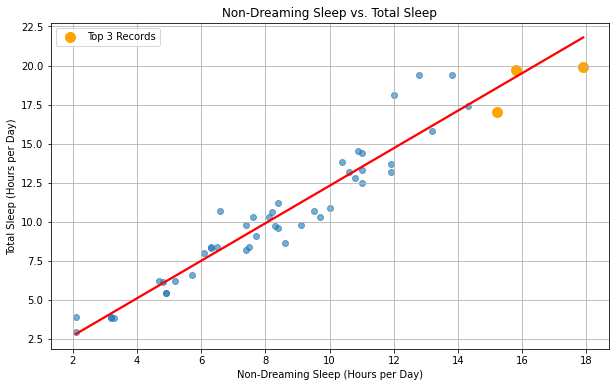

In [14]:
# Inspect the three records with the longest non-dreaming sleep.
top_three = sleep_df.nlargest(3, "non_dreaming_sleep")

display(top_three[[
    "species",
    "non_dreaming_sleep",
    "dreaming_sleep",
    "total_sleep"
]])

plt.figure(figsize=(10, 6))

sns.regplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"},
    ci=None
)

plt.scatter(
    top_three["non_dreaming_sleep"],
    top_three["total_sleep"],
    color="orange",
    s=100,
    label="Top 3 Records"
)

plt.title("Non-Dreaming Sleep vs. Total Sleep")
plt.xlabel("Non-Dreaming Sleep (Hours per Day)")
plt.ylabel("Total Sleep (Hours per Day)")
plt.legend()
plt.grid(True)
plt.show()

## Step 5: Conclusion

**Research question:** How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?

**Do mammals that spend more time in dreaming sleep also tend to spend more time in non-dreaming sleep? Which phase is more strongly related to total sleep? Support your answers with the plots, correlations, and R-squared values. Did the results match your prediction?**

Your answer:  Yes. Mammals that spend more time in dreaming sleep
generally tend to spend more time in non-dreaming sleep.
The correlation is 0.5143, indicating a moderate
positive relationship.

Non-dreaming sleep has the stronger relationship with
total sleep (r = 0.9627, R-squared = 0.9268), compared
with dreaming sleep (r = 0.7271, R-squared = 0.5287).

The results support my original prediction. Non-dreaming
sleep accounts for a larger portion of total sleep and
has a stronger linear relationship with it.

However, this relationship is partly mathematical
because total sleep is calculated using both sleep phases.

## Step 6: Limitation

**State two limitations specific to these sleep relationships. Explain why a stronger correlation is not automatically a better scientific explanation.**

Your answer:  1. The dataset contains historical measurements from
   62 mammal species, with only 48 complete records
   available for these comparisons. Missing measurements
   and differences between species limit how broadly
   the results can be applied.

2. Total sleep is calculated by adding dreaming and
   non-dreaming sleep. This naturally produces strong
   correlations with its components, especially
   non-dreaming sleep.

A stronger correlation does not automatically mean
a better scientific explanation. Correlation measures
the strength of a relationship, but it does not prove
causation or explain the biological mechanisms
behind mammalian sleep patterns.

# Investigation 2: Do danger and predation add information?

## Step 1: Question

**Do danger and predation categories add information about total sleep beyond non-dreaming sleep?**

**Predict whether each index will add substantial, small, or little visible information. What would you look for at comparable non-dreaming-sleep durations?**

Your answer:   I predict that danger and predation ratings will add
a small amount of information beyond non-dreaming sleep.

At similar non-dreaming sleep durations, I would look
for differences in total sleep between mammals with
different danger and predation ratings.

If the groups show noticeable separation, the ratings
may provide additional information. If the points and
regression lines overlap significantly, their added
predictive value is likely limited.

## Step 2: Data

Reuse `sleep_df` and its original sleep measurements. Count records for each danger and predation rating and display a cross-tabulation of the two indices. Keep all five original levels in their natural order. Higher predation index values mean a mammal is more likely to be preyed upon. Higher danger index values mean greater overall danger from other animals.

In [15]:
# Count the records at each danger and predation level.
print("Danger Index Counts:")
print(sleep_df["danger_index"].value_counts().sort_index())

print("\nPredation Index Counts:")
print(sleep_df["predation_index"].value_counts().sort_index())

Danger Index Counts:
1    14
2    12
3     8
4     9
5     5
Name: danger_index, dtype: int64

Predation Index Counts:
1    10
2    13
3     9
4     7
5     9
Name: predation_index, dtype: int64


In [16]:
# Cross-tabulate danger and predation ratings.
pd.crosstab(
    sleep_df["danger_index"],
    sleep_df["predation_index"]
).reindex(
    index=[1, 2, 3, 4, 5],
    columns=[1, 2, 3, 4, 5],
    fill_value=0
)

predation_index,1,2,3,4,5
danger_index,,,,,
1,10,4,0,0,0
2,0,9,3,0,0
3,0,0,5,2,1
4,0,0,1,5,3
5,0,0,0,0,5


## Step 3: Evidence

Use `sns.lmplot()` twice on the non-dreaming–total sleep relationship, once colored by `danger_index` and once by `predation_index`. Set `hue_order=[1, 2, 3, 4, 5]`, use a named palette, and label the legend so the index direction is clear. The separate lines show group patterns; small groups may produce unstable lines. Compare groups where their non-dreaming-sleep ranges overlap.

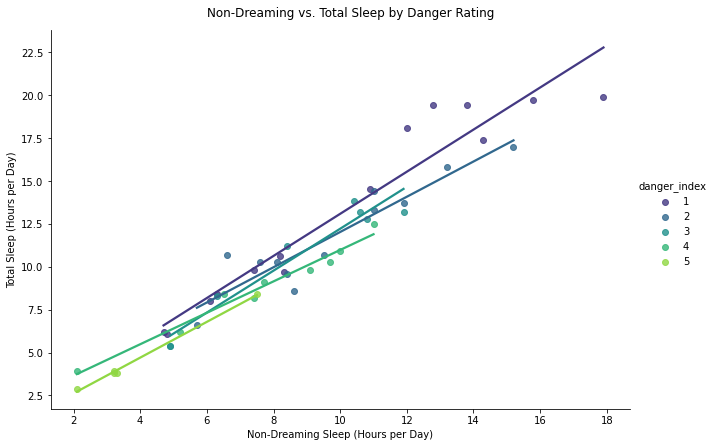

In [17]:
# Plot the non-dreaming–total sleep relationship by danger category.
g = sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="danger_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    ci=None,
    height=6,
    aspect=1.5
)

g.set_axis_labels(
    "Non-Dreaming Sleep (Hours per Day)",
    "Total Sleep (Hours per Day)"
)

g.fig.suptitle(
    "Non-Dreaming vs. Total Sleep by Danger Rating",
    y=1.03
)

plt.show()

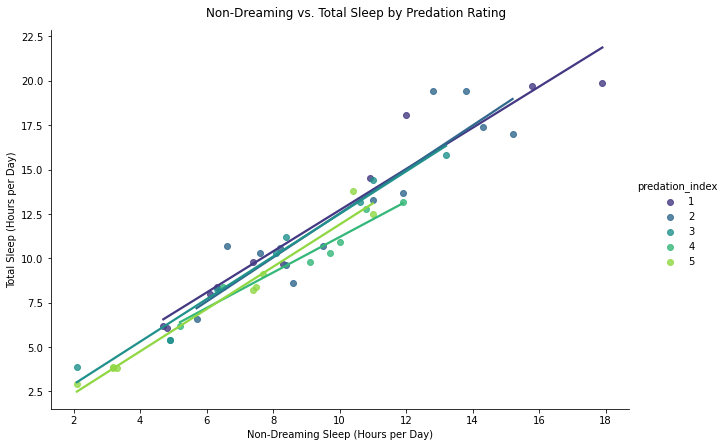

In [18]:
# Plot the non-dreaming–total sleep relationship by predation category.
g = sns.lmplot(
    data=sleep_df,
    x="non_dreaming_sleep",
    y="total_sleep",
    hue="predation_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    ci=None,
    height=6,
    aspect=1.5
)

g.set_axis_labels(
    "Non-Dreaming Sleep (Hours per Day)",
    "Total Sleep (Hours per Day)"
)

g.fig.suptitle(
    "Non-Dreaming vs. Total Sleep by Predation Rating",
    y=1.03
)

plt.show()

**Describe overlap and separation in each plot. How do the group sizes and available non-dreaming-sleep ranges affect your interpretation?**

Your answer:   Both plots show positive relationships between
non-dreaming sleep and total sleep. The danger and
predation groups overlap, although some differences
appear between their regression lines.

Higher danger and predation ratings generally occur
among mammals with shorter sleep durations. However,
the groups do not occupy identical ranges.

Danger rating 1 contains 14 mammals, while rating 5
contains only 5. Predation groups contain between
7 and 13 mammals.

Smaller groups produce less reliable regression lines,
especially outside their observed data ranges.

These differences make it important to compare groups
only where their non-dreaming sleep measurements overlap.
The graphs suggest possible additional information,
but they do not establish a causal relationship.

### Compare model R-squared

The supplied helper follows the lecture's least-squares calculation. Read and run it; you do not need to recreate its matrix operations. `pd.get_dummies()` represents each rating with category indicators. `drop_first=True` chooses a reference level. This avoids assuming equal distances between index values.

These are **additive models**: one shared slope for the quantitative predictor and category-specific intercept adjustments. They differ from the separate group slopes in `lmplot()`. Compare the baseline, baseline plus danger, baseline plus predation, and baseline plus both, all on identical rows and the same response scale. Training R-squared cannot decrease when predictors are added to these nested models; an increase alone does not establish improved performance on new observations.

In [19]:
def calculate_r_squared(data, predictor, response, categorical_features):
    predictors = pd.get_dummies(
        data[[predictor, *categorical_features]],
        columns=categorical_features, drop_first=True, dtype=float
    )
    predictors.insert(0, "intercept", 1.0)
    x = predictors.to_numpy(dtype=float)
    y = data[response].to_numpy(dtype=float)
    fitted = x @ np.linalg.lstsq(x, y, rcond=None)[0]
    return 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()

In [20]:
# Build and display phase_comparison for the four models.
def calculate_r_squared(data, predictor, response, categorical_features):
    predictors = pd.get_dummies(
        data[[predictor, *categorical_features]],
        columns=categorical_features,
        drop_first=True,
        dtype=float
    )
    predictors.insert(0, "intercept", 1.0)
    x = predictors.to_numpy(dtype=float)
    y = data[response].to_numpy(dtype=float)
    fitted = x @ np.linalg.lstsq(x, y, rcond=None)[0]
    return 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()

## Step 4: Check

For each danger rating, display the smallest and largest non-dreaming sleep values using `.groupby()` and `.agg(["min", "max"])`. Repeat for predation ratings.

Compare these ranges with the group plots. Use the ranges to identify where two groups actually have observations at similar non-dreaming sleep durations.

In [21]:
# Display the non-dreaming sleep range for each danger and predation rating.
models = {
    "Non-Dreaming Sleep Only": [],
    "Non-Dreaming + Danger": ["danger_index"],
    "Non-Dreaming + Predation": ["predation_index"],
    "Non-Dreaming + Both": ["danger_index", "predation_index"]
}

results = {}

for name, features in models.items():
    results[name] = calculate_r_squared(
        sleep_df,
        "non_dreaming_sleep",
        "total_sleep",
        features
    )

phase_comparison = pd.DataFrame({
    "Model": list(results.keys()),
    "R_squared": list(results.values())
})

phase_comparison["Improvement"] = (
    phase_comparison["R_squared"] -
    phase_comparison["R_squared"].iloc[0]
)

display(phase_comparison.round(4))

,Model,R_squared,Improvement
0,Non-Dreaming Sleep Only,0.9268,0.0000
1,Non-Dreaming + Danger,0.9427,0.0158
2,Non-Dreaming + Predation,0.9371,0.0103
3,Non-Dreaming + Both,0.9515,0.0246


**Choose two danger groups. Over what range of non-dreaming sleep do both groups have observations? Why should you compare their lines within that shared range?**

Your answer:  I chose danger ratings 1 and 2.

Danger rating 1 ranges from 4.7 to 17.9 hours
of non-dreaming sleep, while danger rating 2
ranges from 5.7 to 15.2 hours.

Their shared range is 5.7 to 15.2 hours.

We should compare their regression lines within
this range because both groups have actual
observations there. Comparing outside the shared
range would involve extrapolation, making the
results less reliable.

## Step 5: Conclusion

**Research question:** Do danger and predation categories add information about total sleep beyond non-dreaming sleep?

**Does adding danger, predation, or both improve the model of total sleep? Report the four R-squared values and how much each changes from non-dreaming sleep alone. Are the improvements small or large? Explain how the group plots support your answer.**

Your answer:  Yes. Adding danger and predation ratings improves
the model's R-squared values.

- Non-dreaming sleep only: 0.9268
- Non-dreaming + danger: 0.9427 (+0.0158)
- Non-dreaming + predation: 0.9371 (+0.0103)
- Non-dreaming + both: 0.9515 (+0.0246)

The improvements are relatively small because
non-dreaming sleep already explains approximately
92.68% of the variation in total sleep.

The model using both ratings achieves the highest
R-squared at 95.15%.

The group plots support these results by showing
some separation between danger and predation
categories, although considerable overlap remains.

These results indicate a modest improvement in
model fit, but they do not establish causation
or guarantee better predictions on new data.

## Step 6: Limitation

**Identify two limitations of this investigation.**

Your answer:  
1. Some danger and predation groups contain very few
   mammals. These small sample sizes make their
   regression lines less reliable, especially
   outside the observed ranges.

2. Danger and predation ratings are related measures,
   and the historical dataset does not represent
   every mammal species. Adding these variables
   improves R-squared, but does not prove causation
   or guarantee better predictions on new data.

# Investigation 3: Gestation time and total sleep

## Step 1: Question

**How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?**

Gestation time is the length of a pregnancy, measured in days. We will compare it with total sleep, measured in hours per day, and see whether taking the logarithm of gestation time makes the pattern look straighter.

**Do you expect mammals with longer pregnancies to sleep more hours per day, fewer hours, or about the same amount? Explain your initial guess. You do not need prior knowledge about mammals; you will compare your prediction with the data.**

Your answer:  
I predict that mammals with longer gestation periods
will generally sleep fewer hours per day.

Larger mammals often have longer pregnancies and may
spend more time feeding or meeting their energy needs.
I expect a negative relationship between gestation
time and total sleep, although other biological and
environmental factors may also influence sleep duration.

## Step 2: Data

Create `gestation_df` by dropping rows missing `gestation_time`, `total_sleep`, `danger_index`, or `predation_index`, then copying the result. How many records were removed from the dataset? Do not drop rows merely because maximum lifespan is missing. Check that gestation is positive and sleep is between 0 and 24 hours per day. Create `log10_gestation_time` only after checking the inputs.

In [22]:
# Prepare gestation_df and check counts and plausible ranges.
gestation_columns = [
    "gestation_time",
    "total_sleep",
    "danger_index",
    "predation_index"
]

gestation_df = mammals_df.dropna(
    subset=gestation_columns
).copy()

print("Original records:", len(mammals_df))
print("Complete records:", len(gestation_df))
print("Records removed:", len(mammals_df) - len(gestation_df))

print("\nGestation times are positive:")
print((gestation_df["gestation_time"] > 0).all())

print("\nTotal sleep is between 0 and 24 hours:")
print(gestation_df["total_sleep"].between(0, 24).all())

gestation_df["log10_gestation_time"] = np.log10(
    gestation_df["gestation_time"]
)

display(gestation_df.head())

Original records: 62
Complete records: 54
Records removed: 8

Gestation times are positive:
True

Total sleep is between 0 and 24 hours:
True


,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index,log10_gestation_time
0,African elephant,6654.000,5712.0,NaN,NaN,3.3,38.6,645.0,3,5,3,2.809560
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3,1.623249
2,Arctic Fox,3.385,44.5,NaN,NaN,12.5,14.0,60.0,1,1,1,1.778151
3,Arctic ground squirrel,0.920,5.7,NaN,NaN,16.5,NaN,25.0,5,2,3,1.397940
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4,2.795185


## Step 3: Evidence

Plot sleep against gestation on original scales, then against log10 gestation, leaving sleep in hours per day. Calculate correlation and simple-line R-squared for each. These R-squared values share the same response scale and observations. Compare whether the points follow a straight or curved pattern and how widely they are scattered, as well as the numerical summaries.

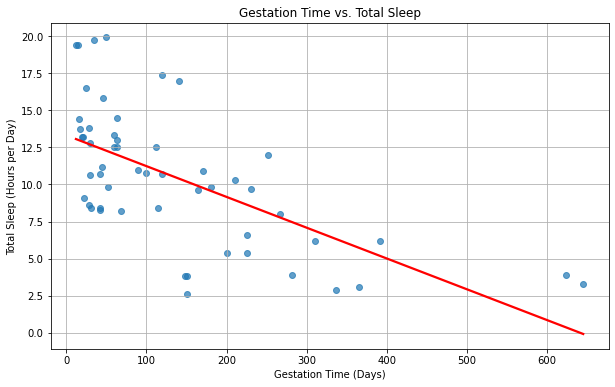

In [23]:
# Plot original gestation and sleep.
plt.figure(figsize=(10, 6))

sns.regplot(
    data=gestation_df,
    x="gestation_time",
    y="total_sleep",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"},
    ci=None
)

plt.title("Gestation Time vs. Total Sleep")
plt.xlabel("Gestation Time (Days)")
plt.ylabel("Total Sleep (Hours per Day)")
plt.grid(True)
plt.show()

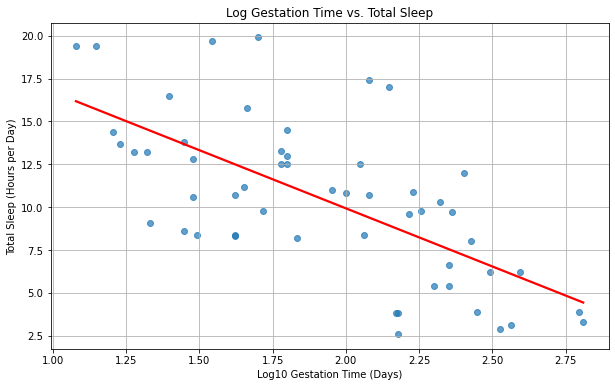

In [24]:
# Plot log gestation and sleep.
plt.figure(figsize=(10, 6))

sns.regplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"},
    ci=None
)

plt.title("Log Gestation Time vs. Total Sleep")
plt.xlabel("Log10 Gestation Time (Days)")
plt.ylabel("Total Sleep (Hours per Day)")
plt.grid(True)
plt.show()

In [25]:
# Calculate the two correlations and squared correlations.
r_original = gestation_df["gestation_time"].corr(
    gestation_df["total_sleep"]
)

r_log = gestation_df["log10_gestation_time"].corr(
    gestation_df["total_sleep"]
)

print("Original Gestation Time:")
print(f"Correlation (r): {r_original:.4f}")
print(f"R-squared: {r_original**2:.4f}")

print("\nLog10 Gestation Time:")
print(f"Correlation (r): {r_log:.4f}")
print(f"R-squared: {r_log**2:.4f}")

Original Gestation Time:
Correlation (r): -0.6313
R-squared: 0.3986

Log10 Gestation Time:
Correlation (r): -0.6637
R-squared: 0.4404


**What changes when gestation is log-transformed? Does the transformation remove the scatter or only improve the straight-line summary modestly?**

Your answer:  

Log-transforming gestation time compresses the larger
values and spreads out the smaller values, making the
relationship with total sleep appear more linear.

The relationship remains negative, meaning mammals
with longer gestation periods generally tend to sleep
fewer hours per day.

The log transformation improves the straight-line fit,
but it does not eliminate the scatter. Considerable
variation remains because gestation time alone cannot
explain all differences in mammalian sleep patterns.

Reuse the group-plot and model-comparison approach from Investigation 2, now using `log10_gestation_time` as the predictor and `total_sleep` as the response. Count observations at each rating level in this subset before interpreting the group lines. Examine danger and predation separately, then compare all four additive models on `gestation_df`.

In [26]:
# Count ratings in the sleep subset.
print("Danger Index Counts:")
print(
    gestation_df["danger_index"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
)

print("\nPredation Index Counts:")
print(
    gestation_df["predation_index"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
)

Danger Index Counts:
1    16
2    12
3    10
4     9
5     7
Name: danger_index, dtype: int64

Predation Index Counts:
1    12
2    14
3     9
4     7
5    12
Name: predation_index, dtype: int64


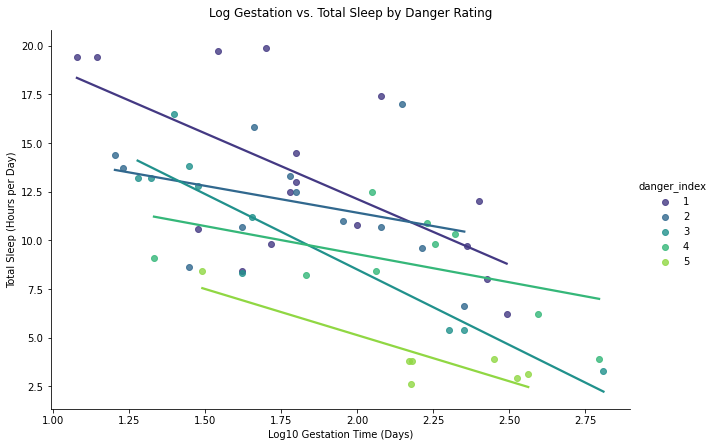

In [27]:
# Plot log gestation and sleep by danger.
g = sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    hue="danger_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    ci=None,
    height=6,
    aspect=1.5
)

g.set_axis_labels(
    "Log10 Gestation Time (Days)",
    "Total Sleep (Hours per Day)"
)

g.fig.suptitle(
    "Log Gestation vs. Total Sleep by Danger Rating",
    y=1.03
)

plt.show()

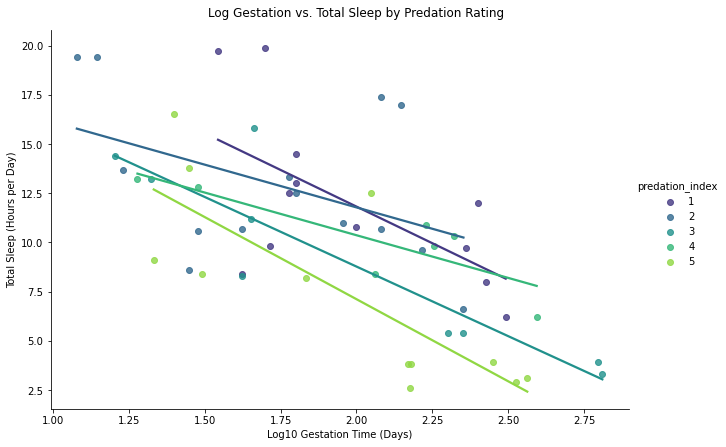

In [28]:
# Plot log gestation and sleep by predation.
g = sns.lmplot(
    data=gestation_df,
    x="log10_gestation_time",
    y="total_sleep",
    hue="predation_index",
    hue_order=[1, 2, 3, 4, 5],
    palette="viridis",
    ci=None,
    height=6,
    aspect=1.5
)

g.set_axis_labels(
    "Log10 Gestation Time (Days)",
    "Total Sleep (Hours per Day)"
)

g.fig.suptitle(
    "Log Gestation vs. Total Sleep by Predation Rating",
    y=1.03
)

plt.show()

In [29]:
# Build and display sleep_comparison for the four models.
models = {
    "Log Gestation Only": [],
    "Log Gestation + Danger": ["danger_index"],
    "Log Gestation + Predation": ["predation_index"],
    "Log Gestation + Both": ["danger_index", "predation_index"]
}

results = {}

for name, features in models.items():
    results[name] = calculate_r_squared(
        gestation_df,
        "log10_gestation_time",
        "total_sleep",
        features
    )

sleep_comparison = pd.DataFrame({
    "Model": list(results.keys()),
    "R_squared": list(results.values())
})

sleep_comparison["Improvement"] = (
    sleep_comparison["R_squared"] -
    sleep_comparison["R_squared"].iloc[0]
)

display(sleep_comparison.round(4))

,Model,R_squared,Improvement
0,Log Gestation Only,0.4404,0.0000
1,Log Gestation + Danger,0.6542,0.2137
2,Log Gestation + Predation,0.5917,0.1512
3,Log Gestation + Both,0.6943,0.2538


## Step 4: Check

For the first five records, display gestation time, its logarithm, and `10 ** log10_gestation_time`. Does reversing the logarithm recover the original number of days?

Display the records with the shortest and longest gestation times. Find their points in both plots and compare the recorded sleep hours with their vertical positions. The horizontal positions change when gestation is transformed; the sleep measurements stay the same.

In [30]:
# Reverse the logarithm for five records and compare with the original gestation times.
log_check = gestation_df[
    ["species", "gestation_time", "log10_gestation_time"]
].head().copy()

log_check["Recovered_Days"] = (
    10 ** log_check["log10_gestation_time"]
)

log_check["Values_Match"] = np.isclose(
    log_check["gestation_time"],
    log_check["Recovered_Days"]
)

display(log_check)

,species,gestation_time,log10_gestation_time,Recovered_Days,Values_Match
0,African elephant,645.0,2.809560,645.0,True
1,African giant pouched rat,42.0,1.623249,42.0,True
2,Arctic Fox,60.0,1.778151,60.0,True
3,Arctic ground squirrel,25.0,1.397940,25.0,True
4,Asian elephant,624.0,2.795185,624.0,True


In [31]:
# Inspect extreme gestation records.
print("Shortest Gestation Times:")
display(
    gestation_df.nsmallest(3, "gestation_time")[
        ["species", "gestation_time",
         "log10_gestation_time", "total_sleep"]
    ]
)

print("Longest Gestation Times:")
display(
    gestation_df.nlargest(3, "gestation_time")[
        ["species", "gestation_time",
         "log10_gestation_time", "total_sleep"]
    ]
)

Shortest Gestation Times:


,species,gestation_time,log10_gestation_time,total_sleep
38,N. American opossum,12.0,1.079181,19.4
60,Water opossum,14.0,1.146128,19.4
22,Golden hamster,16.0,1.204120,14.4


Longest Gestation Times:


,species,gestation_time,log10_gestation_time,total_sleep
0,African elephant,645.0,2.809560,3.3
4,Asian elephant,624.0,2.795185,3.9
7,Brazilian tapir,392.0,2.593286,6.2


**Did reversing the logarithm recover the original gestation times? For the shortest and longest gestation records, do both plots show the recorded total sleep values? Describe what changed between the plots and what stayed the same.**

Your answer:  Yes. Reversing the logarithm recovered the original
gestation times, with only minor floating-point
rounding differences.

The North American opossum had the shortest gestation
time at 12 days, with 19.4 hours of total sleep.
The African elephant had the longest at 645 days,
with 3.3 hours of total sleep.

Both plots show the recorded total sleep values
at their corresponding positions.

The log transformation changed the horizontal
positions by compressing larger gestation values.
The vertical positions remained unchanged because
total sleep was not transformed.

## Step 5: Conclusion

**Research question:** How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?

**Do mammals with longer gestation times tend to sleep more or less? Does using log gestation make the pattern look straighter? Do danger and predation add information? Support your answers with the plots, correlation, and R-squared values, and compare the results with your prediction.**

Your answer:  Mammals with longer gestation periods generally
tend to sleep fewer hours per day.

The original gestation relationship has a correlation
of -0.6313 and an R-squared of 0.3986.

After applying the log transformation, the correlation
improves to -0.6637, with an R-squared of 0.4404.
This makes the relationship slightly more linear,
although considerable scatter remains.

Adding danger and predation ratings improves the model:

- Log gestation only: R-squared = 0.4404
- Log gestation + danger: R-squared = 0.6542
- Log gestation + predation: R-squared = 0.5917
- Log gestation + both: R-squared = 0.6943

The combined model explains approximately 69.43%
of the variation in total sleep.

These results support my original prediction that
mammals with longer pregnancies generally sleep less.

Danger and predation provide additional information,
but improved model fit does not establish causation
or guarantee better predictions on new observations.

## Step 6: Limitation

**Identify two limitations of the gestation and sleep investigation.**

Your answer:  1. The dataset contains a limited number of mammal species,
   and some observations have missing values. Removing
   incomplete records reduces the sample size and may
   affect how well the findings represent other mammals.

2. Gestation time, danger, and predation do not capture
   every factor influencing sleep. Other biological and
   environmental differences may explain some of the
   remaining variation. Correlation also does not
   establish causation.

## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:  I used AI as a resource to help troubleshoot code, clarify concepts, and explore different approaches to the analysis. I reviewed the results, worked through the exercises, and used what I learned to interpret the data and draw conclusions.

## Submission checklist

- Use the supplied CSV with a relative path.
- Complete the dictionary table and every written response.
- Include a prediction and all six workflow steps for each investigation.
- Include all three sleep comparison plots, two non-dreaming–total group plots, original and log-gestation sleep plots, and two sleep group plots.
- Keep observations consistent within each comparison; report counts and investigate exclusions.
- Interpret correlation and R-squared on the correct scale, using numerical and visual evidence.
- Compare baseline, danger, predation, and combined models without claiming automatic causal or predictive improvement.
- Explain whether the patterns are straight or curved, how the log transformation changes the gestation plot, and what the analyses cannot tell us.
- Complete the AI-use reflection, restart the kernel, and run the notebook in order before submitting.